# Notebook 01 — Tiền xử lý và phân tích khám phá dữ liệu WHO

Notebook này có thể chạy lại từ thư mục gốc của dự án. Quy trình chính được thực hiện trong `src/run_eda.py`; notebook dùng để kiểm tra, khám phá và trình bày kết quả. File WHO gốc được giữ nguyên.

In [1]:
from pathlib import Path
import subprocess, sys
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / "src" / "run_eda.py").exists():
    ROOT = ROOT.parent
assert (ROOT / "src" / "run_eda.py").exists(), "Hãy mở notebook từ thư mục notebooks hoặc thư mục gốc dự án."

subprocess.run([sys.executable, str(ROOT / "src" / "run_eda.py")], check=True, cwd=ROOT)
DATA = ROOT / "data"


{
  "raw_rows": 5347,
  "raw_columns": 50,
  "clean_rows": 5347,
  "clean_columns": 48,
  "app_columns": 25,
  "iso3_entities": 217,
  "year_min": 2000,
  "year_max": 2024,
  "duplicate_iso3_year": 0,
  "all_null_columns_removed": [
    "e_tbhiv_prct_lo",
    "e_tbhiv_prct_hi"
  ],
  "kmeans_candidates_latest_year": 193
}


## 1. Quy mô và cấu trúc dữ liệu

In [2]:
raw = pd.read_csv(DATA / "raw" / "TB_burden_countries_2026-10-29.csv")
clean = pd.read_csv(DATA / "TB_cleaned_full.csv")
app = pd.read_csv(DATA / "TB_country_year.csv")
dictionary = pd.read_csv(DATA / "TB_data_dictionary.csv")

print("Raw:", raw.shape, "Clean:", clean.shape, "Dashboard table:", app.shape)
print("Year range:", int(app.year.min()), "-", int(app.year.max()))
print("ISO3 entities:", app.iso3.nunique())
print("Duplicate ISO3-year:", app.duplicated(["iso3", "year"]).sum())
display(app.head())


Raw: (5347, 50) Clean: (5347, 48) Dashboard table: (5347, 25)
Year range: 2000 - 2024
ISO3 entities: 217
Duplicate ISO3-year: 0


,country,iso2,iso3,g_whoregion,year,e_pop_num,e_inc_100k,e_inc_100k_lo,e_inc_100k_hi,e_inc_num,e_inc_num_lo,e_inc_num_hi,e_mort_100k,e_mort_100k_lo,e_mort_100k_hi,e_mort_num,e_mort_num_lo,e_mort_num_hi,c_newinc_100k,c_cdr,c_cdr_lo,c_cdr_hi,cfr_pct,cfr_pct_lo,cfr_pct_hi
0,Afghanistan,AF,AFG,EMR,2000,20130323,148.0,46.0,1510.0,30000.0,9200.0,305000.0,50.0,32.0,70.0,10000.0,6500.0,14000.0,35.0,24.0,2.3,77.0,34.0,19.0,50.0
1,Afghanistan,AF,AFG,EMR,2001,20284311,175.0,66.0,1320.0,35000.0,13000.0,267000.0,55.0,37.0,76.0,11000.0,7600.0,15000.0,50.0,29.0,3.8,76.0,32.0,20.0,46.0
2,Afghanistan,AF,AFG,EMR,2002,21378110,197.0,83.0,1140.0,42000.0,18000.0,245000.0,59.0,41.0,80.0,13000.0,8700.0,17000.0,65.0,33.0,5.6,78.0,30.0,19.0,42.0
3,Afghanistan,AF,AFG,EMR,2003,22733047,215.0,97.0,992.0,49000.0,22000.0,225000.0,68.0,48.0,92.0,15000.0,11000.0,21000.0,61.0,28.0,6.1,63.0,32.0,21.0,44.0
4,Afghanistan,AF,AFG,EMR,2004,23560660,228.0,109.0,862.0,54000.0,26000.0,203000.0,67.0,47.0,89.0,16000.0,11000.0,21000.0,78.0,34.0,9.1,72.0,29.0,20.0,40.0


## 2. Chất lượng và độ đầy đủ dữ liệu

In [3]:
quality = pd.read_csv(DATA / "TB_data_quality_summary.csv")
coverage = pd.read_csv(DATA / "TB_year_coverage.csv")
display(quality)
print("Missing c_cdr:", int(app.c_cdr.isna().sum()))
print("c_cdr > 100:", int((app.c_cdr > 100).sum()))
print("Missing incidence rate:", int(app.e_inc_100k.isna().sum()))
print("Missing mortality rate:", int(app.e_mort_100k.isna().sum()))
display(coverage.tail())


,indicator,column,missing,available,completeness_pct
0,Tỷ suất mắc mới ước tính,e_inc_100k,25,5322,99.532448
1,Số ca mắc mới ước tính,e_inc_num,25,5322,99.532448
2,Tỷ suất tử vong ước tính,e_mort_100k,25,5322,99.532448
3,Số ca tử vong ước tính,e_mort_num,25,5322,99.532448
4,Tỷ lệ phát hiện ca bệnh (c_cdr),c_cdr,364,4983,93.192444
5,Dân số ước tính,e_pop_num,0,5347,100.000000


Missing c_cdr: 364
c_cdr > 100: 8
Missing incidence rate: 25
Missing mortality rate: 25


,year,entities,incidence_available,mortality_available,cdr_available
20,2020,215,214,214,203
21,2021,215,214,214,200
22,2022,215,214,214,201
23,2023,215,214,214,202
24,2024,215,214,214,193


## 3. Đối chiếu định nghĩa biến với Data Dictionary

In [4]:
variables = ["e_pop_num", "e_inc_100k", "e_inc_num", "e_mort_100k", "e_mort_num", "c_newinc_100k", "c_cdr"]
display(dictionary[dictionary.variable_name.isin(variables)][["variable_name", "dataset", "definition"]])


,variable_name,dataset,definition
147,c_cdr,Estimates,Case detection rate (all forms) [also known as...
150,c_newinc_100k,Estimates,"Case notification rate, which is the total of ..."
157,e_inc_100k,Estimates,Estimated incidence (all forms) per 100 000 po...
160,e_inc_num,Estimates,Estimated number of incident cases (all forms)
172,e_mort_100k,Estimates,Estimated mortality of TB cases (all forms) pe...
181,e_mort_num,Estimates,Estimated number of deaths from TB (all forms)
190,e_pop_num,Estimates,Estimated total population number


## 4. Phân tích Việt Nam

,year,e_inc_100k,e_inc_num,e_mort_100k,e_mort_num,c_newinc_100k,c_cdr
5237,2015,199.0,185000.0,18.0,17000.0,109.0,54.0
5238,2016,193.0,182000.0,16.0,15000.0,109.0,56.0
5239,2017,188.0,179000.0,15.0,14000.0,108.0,57.0
5240,2018,182.0,175000.0,13.0,13000.0,104.0,57.0
5241,2019,176.0,171000.0,12.0,12000.0,105.0,60.0
5242,2020,171.0,168000.0,12.0,12000.0,102.0,59.0
5243,2021,171.0,169000.0,12.0,12000.0,78.0,46.0
5244,2022,178.0,177000.0,14.0,14000.0,103.0,58.0
5245,2023,185.0,185000.0,13.0,13000.0,104.0,56.0
5246,2024,182.0,184000.0,12.0,12000.0,105.0,58.0


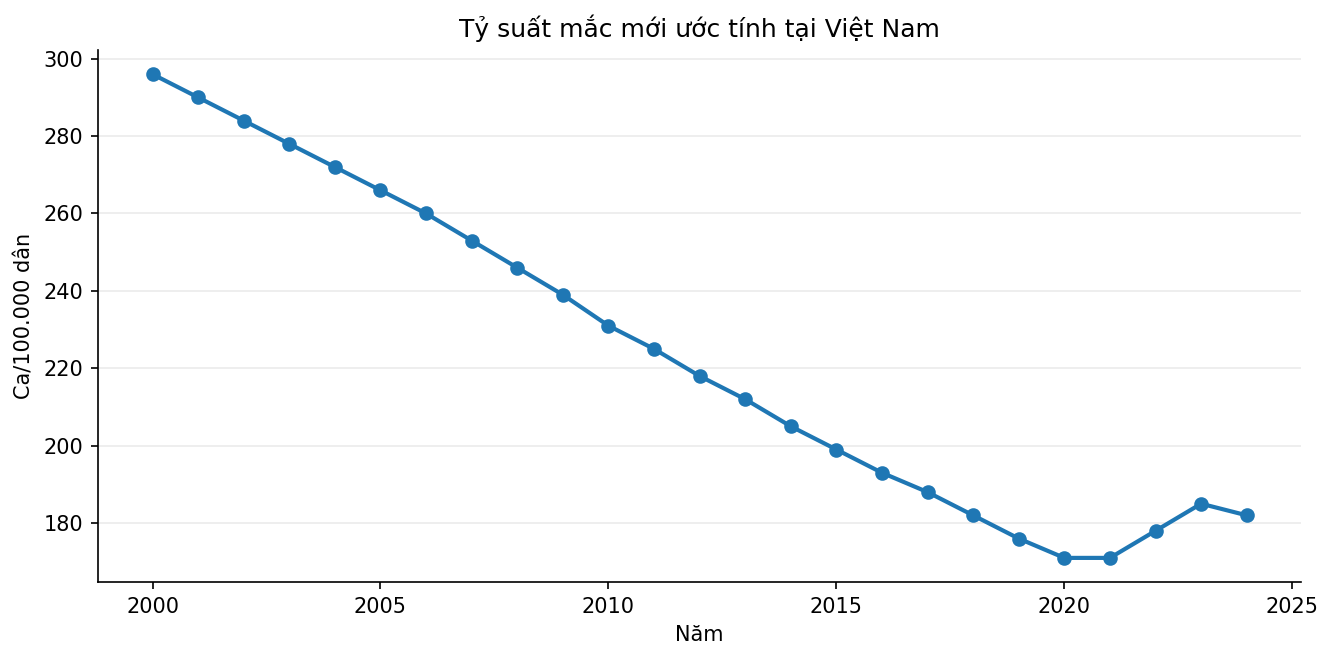

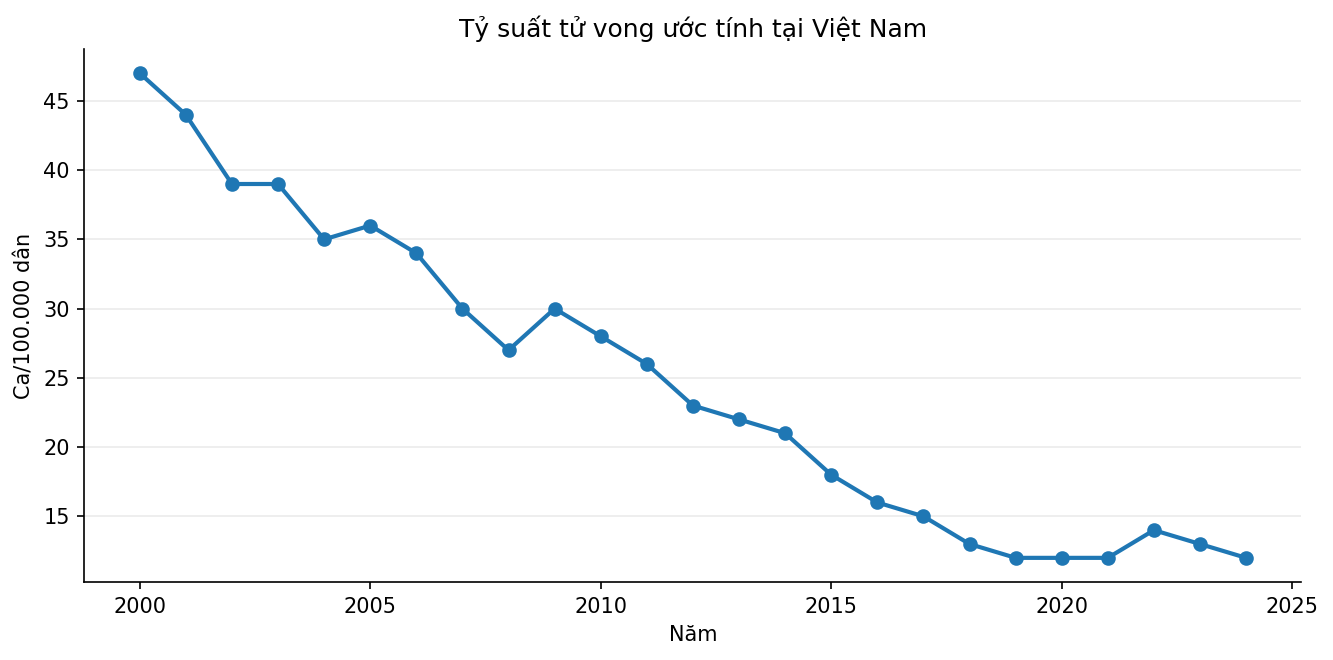

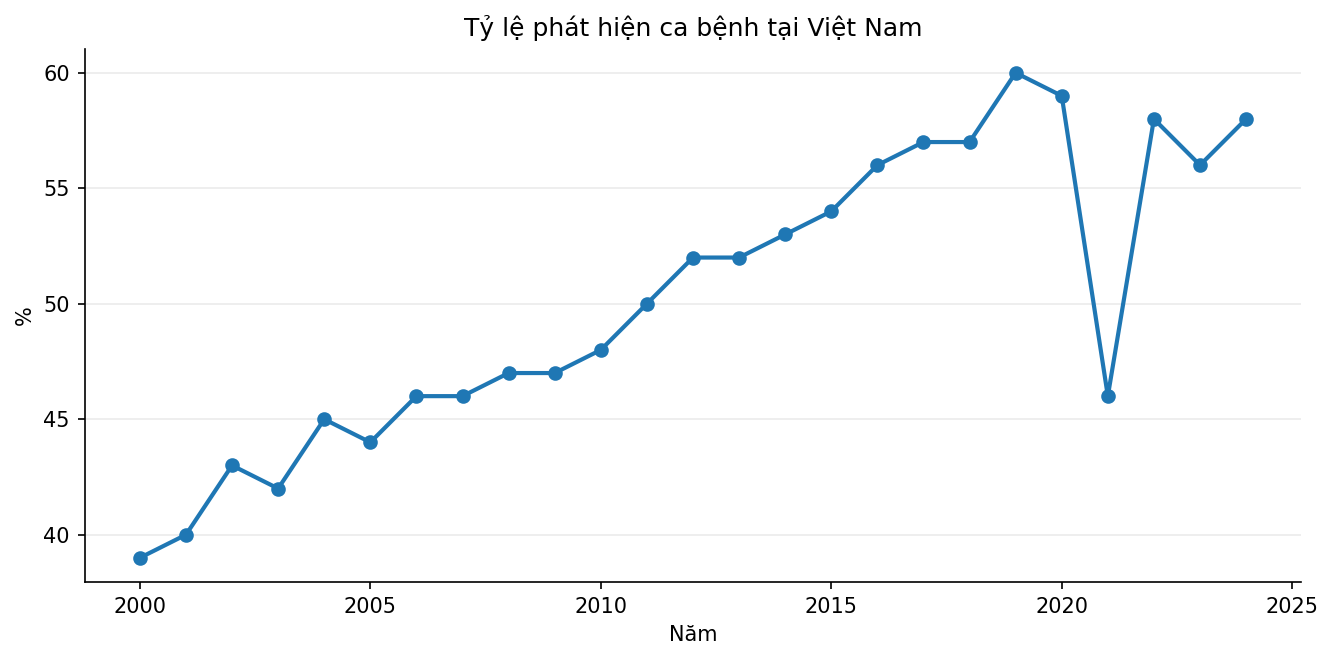

In [5]:
vietnam = app[app.iso3.eq("VNM")].sort_values("year")
display(vietnam[["year", "e_inc_100k", "e_inc_num", "e_mort_100k", "e_mort_num", "c_newinc_100k", "c_cdr"]].tail(10))
for filename in ["01_vietnam_incidence_trend.png", "02_vietnam_mortality_trend.png", "03_vietnam_cdr_trend.png"]:
    display(Image(filename=str(ROOT / "reports" / "figures" / filename)))


## 5. So sánh quốc gia năm 2024

Top theo tỷ suất mắc mới trên 100.000 dân


,country,g_whoregion,e_inc_100k,e_inc_num
2564,Kiribati,WPR,945.0,1300.0
3744,Papua New Guinea,WPR,664.0,70000.0
3819,Philippines,WPR,625.0,724000.0
2714,Lesotho,AFR,548.0,13000.0
4746,Timor-Leste,SEA,496.0,6900.0
1464,Djibouti,EMR,495.0,5800.0
3259,Myanmar,SEA,482.0,263000.0
3139,Mongolia,WPR,446.0,16000.0
3284,Namibia,AFR,422.0,13000.0
974,Central African Republic,AFR,419.0,22000.0


Top theo số ca mắc mới ước tính


,country,g_whoregion,e_inc_100k,e_inc_num
2264,India,SEA,187.0,2710000.0
2289,Indonesia,WPR,382.0,1080000.0
3819,Philippines,WPR,625.0,724000.0
1049,China,WPR,49.0,696000.0
3669,Pakistan,EMR,266.0,669000.0
3494,Nigeria,AFR,219.0,510000.0
1414,Democratic Republic of the Congo,AFR,377.0,412000.0
424,Bangladesh,SEA,221.0,384000.0
3259,Myanmar,SEA,482.0,263000.0
4484,South Africa,AFR,389.0,249000.0


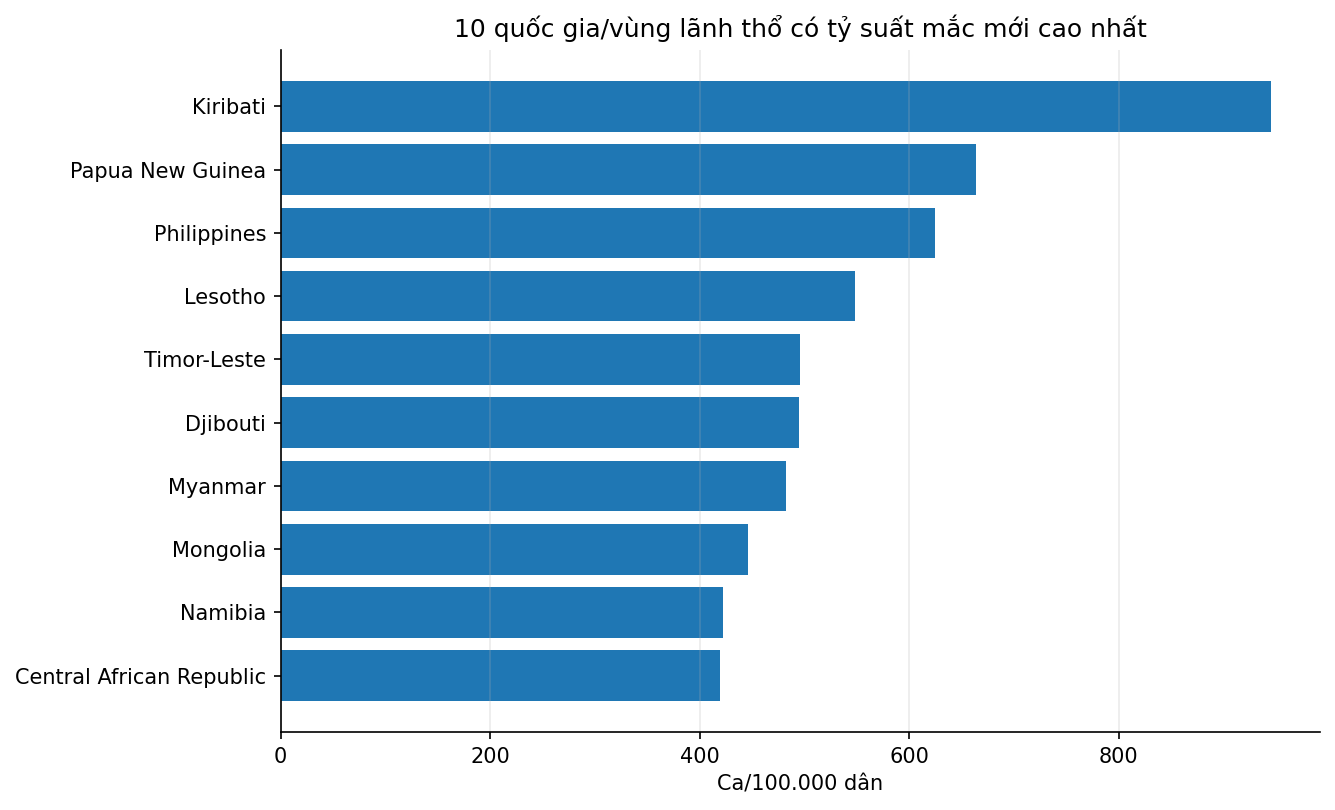

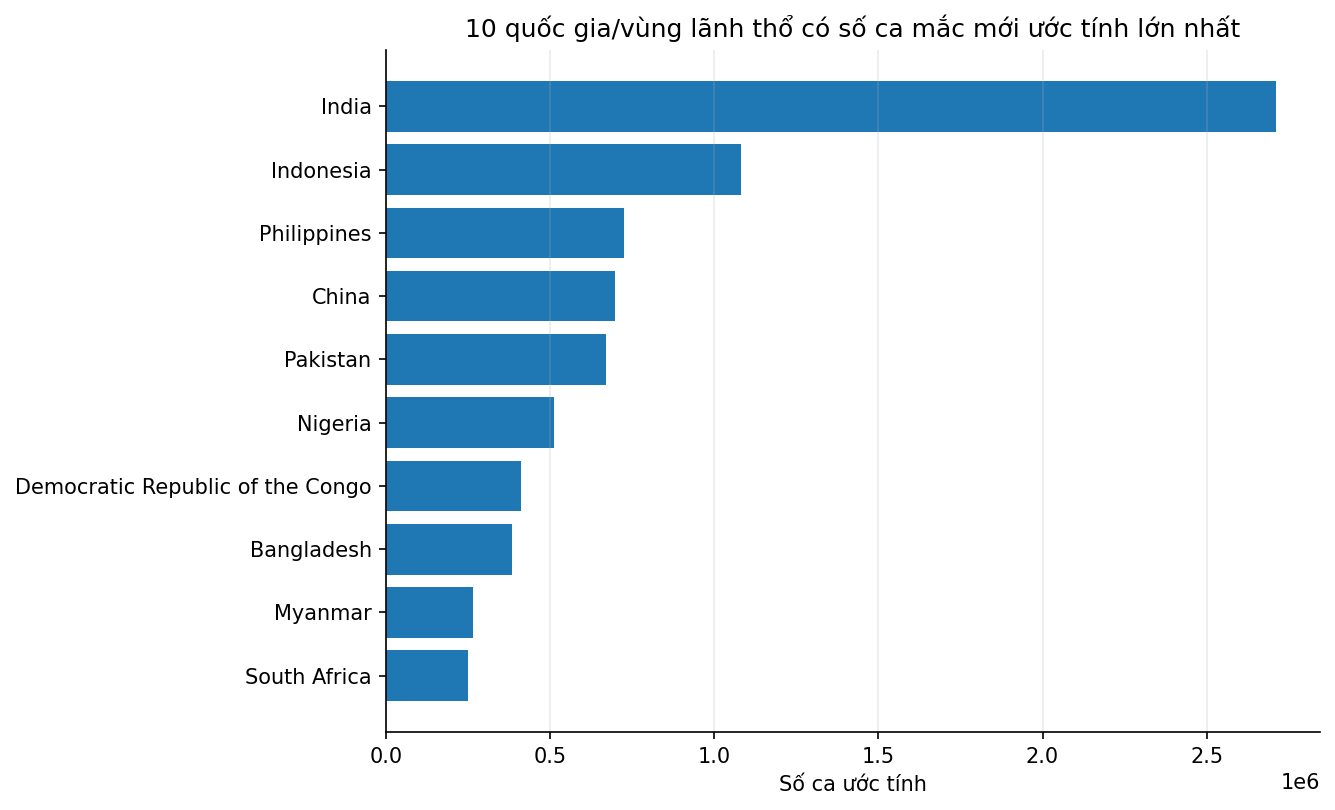

In [6]:
latest = app[app.year.eq(int(app.year.max()))].copy()
top_rate = latest.dropna(subset=["e_inc_100k"]).nlargest(10, "e_inc_100k")
top_cases = latest.dropna(subset=["e_inc_num"]).nlargest(10, "e_inc_num")
print("Top theo tỷ suất mắc mới trên 100.000 dân")
display(top_rate[["country", "g_whoregion", "e_inc_100k", "e_inc_num"]])
print("Top theo số ca mắc mới ước tính")
display(top_cases[["country", "g_whoregion", "e_inc_100k", "e_inc_num"]])
display(Image(filename=str(ROOT / "reports" / "figures" / "04_top10_incidence_rate.png")))
display(Image(filename=str(ROOT / "reports" / "figures" / "05_top10_incident_cases.png")))


## 6. Tỷ suất tổng hợp theo năm — phép tính của đồ án

,year,incidence_entities,mortality_entities,incidence_cases_estimated,incidence_population_covered,incidence_rate_project_aggregate,mortality_cases_estimated,mortality_population_covered,mortality_rate_project_aggregate
15,2015,214,214,11015698.0,7416403614,148.531533,1731706.0,7416403614,23.349673
16,2016,214,214,10759475.0,7504282215,143.377803,1649151.0,7504282215,21.976132
17,2017,214,214,10610420.0,7591149686,139.773558,1566162.0,7591149686,20.631420
18,2018,214,214,10452823.0,7675280131,136.188163,1478186.0,7675280131,19.259050
19,2019,214,214,10307117.0,7756550516,132.882742,1397183.0,7756550516,18.012943
20,2020,214,214,10173717.0,7832152186,129.896825,1389311.0,7832152186,17.738560
21,2021,214,214,10319052.0,7899598997,130.627542,1402435.0,7899598997,17.753243
22,2022,214,214,10600103.0,7966610048,133.056632,1327167.0,7966610048,16.659118
23,2023,214,214,10653626.0,8036949170,132.558086,1241137.0,8036949170,15.442887
24,2024,214,214,10553581.0,8107197869,130.175446,1198800.0,8107197869,14.786860


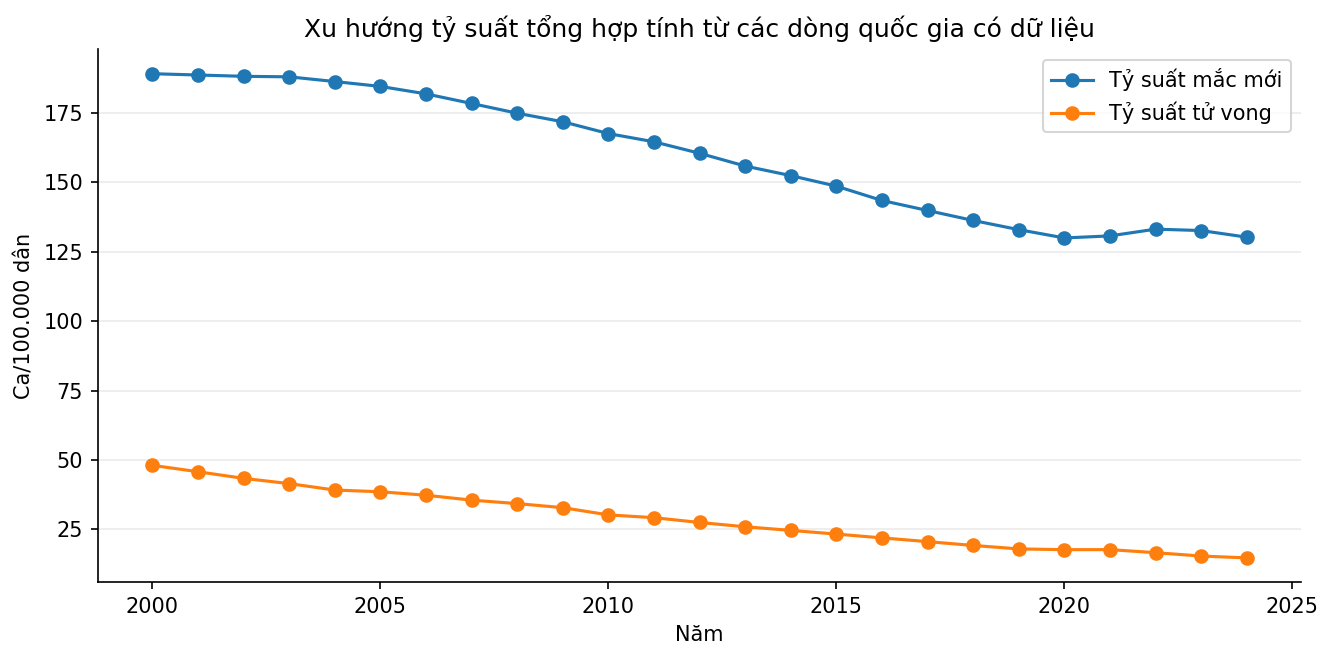

In [7]:
yearly = pd.read_csv(DATA / "TB_yearly_weighted_summary.csv")
display(yearly.tail(10))
display(Image(filename=str(ROOT / "reports" / "figures" / "06_project_weighted_global_trends.png")))


## 7. Phát hiện ban đầu và giới hạn diễn giải

- Năm 2024, quốc gia có tỷ suất mắc mới ước tính cao nhất trong file là Kiribati; quốc gia có số ca mắc mới ước tính lớn nhất là Ấn Độ. Hai thứ hạng dùng hai thước đo khác nhau.
- Tỷ suất tổng hợp trong notebook được tính từ tổng số ca ước tính chia cho tổng dân số ở các thực thể có dữ liệu, nhân 100.000. Đây là phép tính của đồ án, không phải chỉ số tổng hợp chính thức của WHO.
- Số thực thể có dữ liệu thay đổi theo năm; chuỗi tổng hợp có thể bị ảnh hưởng bởi mức độ bao phủ dữ liệu.
- Các ước tính WHO có bất định; cần xem cận thấp/cao khi phân tích sâu.
- Xu hướng và tương quan mô tả không chứng minh quan hệ nhân quả.